# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** Harshit Venkatesh Horakeri &nbsp;&nbsp; **Roll No.:** 1RUA25CSE0184 &nbsp;&nbsp; **Date:** 06-11-2026

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

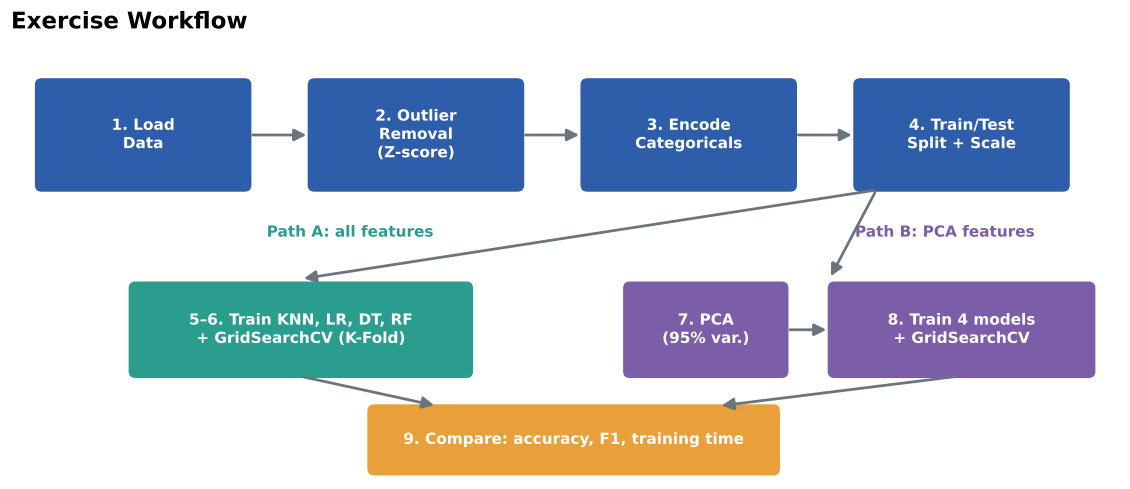

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [5]:
import os
from pathlib import Path
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [6]:
import pandas as pd
from pathlib import Path

data_path = Path("heart.xls")

if not data_path.exists():
    raise FileNotFoundError("heart.xls not found!")

# Detect the actual file format
with open(data_path, "rb") as f:
    file_header = f.read(8)

print("File header:", file_header)

if file_header.startswith(b"PK"):
    df = pd.read_excel(data_path, engine="openpyxl")

elif file_header.startswith(b"\xD0\xCF\x11\xE0"):
    df = pd.read_excel(data_path, engine="xlrd")

else:
    df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

File header: b'Age,Sex,'
Dataset loaded successfully!
Dataset shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [7]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))

Dataset shape: (918, 12)

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:


,Data type
Age,int64
Sex,str
ChestPainType,str
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,str
MaxHR,int64
ExerciseAngina,str
Oldpeak,float64


### 1.3 Check for missing values

In [8]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))
print("\nTotal missing values:", int(df.isnull().sum().sum()))

Missing values in each column:


,Missing values
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0



Total missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

In [9]:
display(df["HeartDisease"].value_counts().rename("Count").to_frame())
display((df["HeartDisease"].value_counts(normalize=True) * 100)
        .round(2).rename("Percentage").to_frame())

,Count
HeartDisease,
1,508
0,410


,Percentage
HeartDisease,
1,55.34
0,44.66


**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

**Answer:** The standard Heart Failure Prediction `heart.csv` dataset contains **918 rows and 12 columns** (11 predictors and the `HeartDisease` target). The text-based columns are `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, and `ST_Slope`. The original dataset generally has no pandas `NaN` values; however, zero values in `Cholesterol` and `RestingBP` should be inspected because they may represent invalid or unrecorded measurements. The code above prints the exact dimensions, data types, and missing-value counts for the copy used in this run.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

*[zscore image omitted: attachment was not included in the notebook]*

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

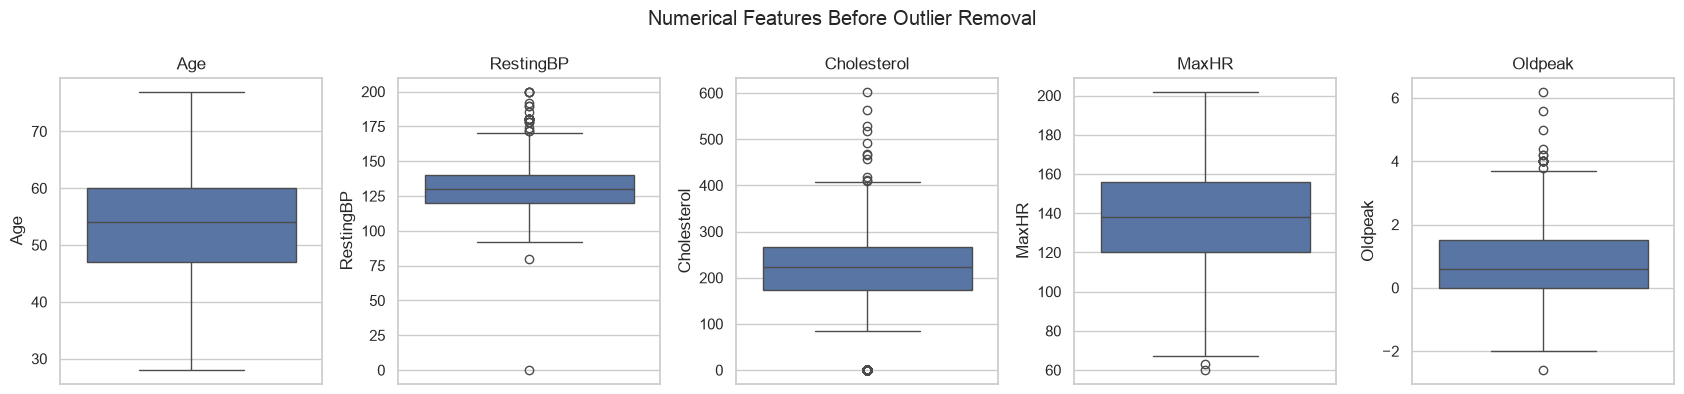

In [10]:
numeric_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, len(numeric_features), figsize=(17, 4))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Numerical Features Before Outlier Removal")
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [11]:
# Z-scores are calculated only for the five continuous numerical features.
z_scores = pd.DataFrame(
    zscore(df[numeric_features], nan_policy="omit"),
    columns=numeric_features,
    index=df.index
)
display(z_scores.head())

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [12]:
outlier_mask = (z_scores.abs() > 3).any(axis=1)
print("Number of records containing at least one outlier:", int(outlier_mask.sum()))
print("\nOutlier count by feature:")
display((z_scores.abs() > 3).sum().sort_values(ascending=False).to_frame("Outlier records"))

Number of records containing at least one outlier: 19

Outlier count by feature:


,Outlier records
RestingBP,8
Oldpeak,7
Cholesterol,3
MaxHR,1
Age,0


### 2.4 Remove the outliers and display the new shape

In [13]:
shape_before = df.shape
df_clean = df.loc[~outlier_mask].copy()
print("Shape before removal:", shape_before)
print("Shape after removal: ", df_clean.shape)
print("Records removed:", shape_before[0] - df_clean.shape[0])

Shape before removal: (918, 12)
Shape after removal:  (899, 12)
Records removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

**Answer:** The exact number of removed records is printed in section 2.4 as the difference between the original and cleaned row counts. A record is removed if **at least one** of `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, or `Oldpeak` has an absolute Z-score greater than 3. The per-feature outlier counts in section 2.3 show which variable contributes the most; counts can overlap because one record may be an outlier in multiple features.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

*[encoding image omitted: attachment was not included in the notebook]*

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [14]:
categorical_features = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()
print("Categorical features:", categorical_features)
for col in categorical_features:
    print(f"\n{col}: {df_clean[col].unique().tolist()}")

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Sex: ['M', 'F']

ChestPainType: ['ATA', 'NAP', 'ASY', 'TA']

RestingECG: ['Normal', 'ST', 'LVH']

ExerciseAngina: ['N', 'Y']

ST_Slope: ['Up', 'Flat', 'Down']


### 3.2 Apply Label Encoding

In [15]:
from sklearn.preprocessing import LabelEncoder

# The assignment specifies label encoding for the binary categorical columns.
binary_features = [c for c in ["Sex", "ExerciseAngina"] if c in df_clean.columns]
label_encoders = {}
df_encoded = df_clean.copy()

for col in binary_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le
    print(f"{col} mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

Sex mapping: {'F': np.int64(0), 'M': np.int64(1)}
ExerciseAngina mapping: {'N': np.int64(0), 'Y': np.int64(1)}


### 3.3 Apply One-Hot Encoding

In [16]:
# Nominal features with more than two categories are one-hot encoded.
nominal_features = [
    c for c in ["ChestPainType", "RestingECG", "ST_Slope"]
    if c in df_encoded.columns
]
df_encoded = pd.get_dummies(
    df_encoded, columns=nominal_features, drop_first=True, dtype=int
)

### 3.4 Display the final encoded dataset

In [17]:
print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.head())
print("\nRemaining data types:")
display(df_encoded.dtypes.to_frame("Data type"))

Encoded dataset shape: (899, 16)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1



Remaining data types:


,Data type
Age,int64
Sex,int64
RestingBP,int64
Cholesterol,int64
FastingBS,int64
MaxHR,int64
ExerciseAngina,int64
Oldpeak,float64
HeartDisease,int64
ChestPainType_ATA,int64


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

**Answer:** `Sex` and `ExerciseAngina` are binary categorical variables, so Label Encoding converts their two categories into 0 and 1. `ChestPainType`, `RestingECG`, and `ST_Slope` are nominal categories with more than two possible values, so One-Hot Encoding is used to avoid creating a false numerical order. With `drop_first=True`, the standard dataset produces **15 predictor columns** after encoding (the target `HeartDisease` is separate). The actual encoded shape is displayed in section 3.4.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

*[leakage image omitted: attachment was not included in the notebook]*

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [18]:
X = df_encoded.drop(columns=["HeartDisease"])
y = df_encoded["HeartDisease"].astype(int)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (899, 15)
y shape: (899,)


### 4.2 Split into training and testing sets

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training features:", X_train.shape)
print("Testing features: ", X_test.shape)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).sort_index().rename("Proportion").to_frame())

Training features: (719, 15)
Testing features:  (180, 15)
Training target distribution:


,Proportion
HeartDisease,
0,0.453408
1,0.546592


### 4.3 Apply feature scaling (fit on training data only)

In [20]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape: ", X_test_scaled.shape)

Scaled training shape: (719, 15)
Scaled testing shape:  (180, 15)


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

**Answer:** I used `StandardScaler` because it centres each feature around a mean of zero and scales it to unit standard deviation. This is useful for KNN and Logistic Regression because their results can be affected by feature magnitudes. The scaler is fitted only on `X_train`; fitting it on the full dataset would allow information from the test set to influence the training transformation (data leakage), making the evaluation less independent and potentially optimistic.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [21]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    """Fit a classifier, time training, and return test metrics plus predictions."""
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    y_pred = model.predict(X_test)
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Training time (s)": training_time,
        "Confusion matrix": confusion_matrix(y_test, y_pred)
    }
    print(f"\n{model_name}")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("Confusion matrix:\n", metrics["Confusion matrix"])
    return metrics, model, y_pred

### 5.2 K-Nearest Neighbors

In [22]:
knn_default_metrics, knn_default, knn_default_pred = evaluate_model(
    KNeighborsClassifier(), X_train_scaled, X_test_scaled, y_train, y_test, "KNN"
)


KNN
              precision    recall  f1-score   support

           0       0.90      0.85      0.87        81
           1       0.88      0.92      0.90        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180

Confusion matrix:
 [[69 12]
 [ 8 91]]


### 5.3 Logistic Regression

In [23]:
lr_default_metrics, lr_default, lr_default_pred = evaluate_model(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression"
)


Logistic Regression
              precision    recall  f1-score   support

           0       0.87      0.84      0.86        81
           1       0.87      0.90      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180

Confusion matrix:
 [[68 13]
 [10 89]]


### 5.4 Decision Tree

In [24]:
dt_default_metrics, dt_default, dt_default_pred = evaluate_model(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree"
)


Decision Tree
              precision    recall  f1-score   support

           0       0.80      0.79      0.80        81
           1       0.83      0.84      0.83        99

    accuracy                           0.82       180
   macro avg       0.81      0.81      0.81       180
weighted avg       0.82      0.82      0.82       180

Confusion matrix:
 [[64 17]
 [16 83]]


### 5.5 Random Forest

In [25]:
rf_default_metrics, rf_default, rf_default_pred = evaluate_model(
    RandomForestClassifier(random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest"
)


Random Forest
              precision    recall  f1-score   support

           0       0.88      0.83      0.85        81
           1       0.87      0.91      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180

Confusion matrix:
 [[67 14]
 [ 9 90]]


### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1-score,Training time (s)
Model,,,,,
KNN,0.8889,0.8835,0.9192,0.9010,0.0019
Logistic Regression,0.8722,0.8725,0.8990,0.8856,0.0045
Decision Tree,0.8167,0.8300,0.8384,0.8342,0.0082
Random Forest,0.8722,0.8654,0.9091,0.8867,0.0921


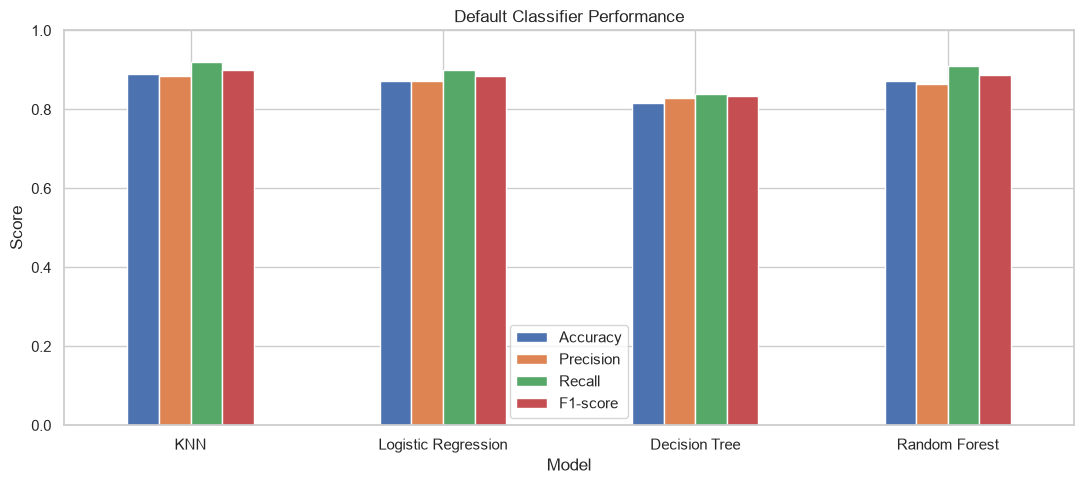

In [26]:
default_results = pd.DataFrame([
    {k: v for k, v in m.items() if k != "Confusion matrix"}
    for m in [knn_default_metrics, lr_default_metrics, dt_default_metrics, rf_default_metrics]
]).set_index("Model")
display(default_results.round(4))

default_results[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0
)
plt.title("Default Classifier Performance")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

**Answer:** The model with the highest test accuracy is the row with the largest Accuracy value in the comparison table in section 5.6. Accuracy alone is not sufficient for medical diagnosis. **Recall is especially important** because it measures the proportion of patients who actually have heart disease that the model correctly detects. A false negative may mean a patient with disease is missed. Precision and F1-score should also be considered to understand false alarms and the balance between precision and recall. A model should not be selected from accuracy alone.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

*[kfold image omitted: attachment was not included in the notebook]*

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    },
    "Logistic Regression": [
        {"C": [0.01, 0.1, 1, 10], "penalty": ["l2"], "solver": ["lbfgs"]},
        {"C": [0.01, 0.1, 1, 10], "penalty": ["l1", "l2"], "solver": ["liblinear"]}
    ],
    "Decision Tree": {
        "max_depth": [None, 3, 5, 8, 12],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5],
        "max_features": ["sqrt", "log2"]
    }
}

### 6.2 Tune KNN

In [28]:
knn_search = GridSearchCV(
    KNeighborsClassifier(), param_grids["KNN"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
knn_search.fit(X_train_scaled, y_train)
print("Best parameters:", knn_search.best_params_)
print("Best mean CV F1:", knn_search.best_score_)

Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best mean CV F1: 0.8932133072665671


### 6.3 Tune Logistic Regression

In [29]:
lr_search = GridSearchCV(
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    param_grids["Logistic Regression"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
lr_search.fit(X_train_scaled, y_train)
print("Best parameters:", lr_search.best_params_)
print("Best mean CV F1:", lr_search.best_score_)

Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best mean CV F1: 0.8812414880819389


### 6.4 Tune Decision Tree

In [30]:
dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grids["Decision Tree"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
dt_search.fit(X_train_scaled, y_train)
print("Best parameters:", dt_search.best_params_)
print("Best mean CV F1:", dt_search.best_score_)

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best mean CV F1: 0.8492476134117917


### 6.5 Tune Random Forest

In [31]:
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grids["Random Forest"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
rf_search.fit(X_train_scaled, y_train)
print("Best parameters:", rf_search.best_params_)
print("Best mean CV F1:", rf_search.best_score_)

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best mean CV F1: 0.8896664281533658


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

In [32]:
tuned_searches = {
    "KNN": knn_search, "Logistic Regression": lr_search,
    "Decision Tree": dt_search, "Random Forest": rf_search
}
tuned_results = []
tuned_models = {}
for name, search in tuned_searches.items():
    metrics, fitted_model, pred = evaluate_model(
        search.best_estimator_, X_train_scaled, X_test_scaled,
        y_train, y_test, name + " (tuned)"
    )
    tuned_models[name] = fitted_model
    tuned_results.append({
        **{k: v for k, v in metrics.items() if k != "Confusion matrix"},
        "Best CV F1": search.best_score_,
        "Best parameters": search.best_params_
    })
tuned_results_df = pd.DataFrame(tuned_results).set_index("Model")
display(tuned_results_df.round(4))


KNN (tuned)
              precision    recall  f1-score   support

           0       0.90      0.86      0.88        81
           1       0.89      0.92      0.91        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180

Confusion matrix:
 [[70 11]
 [ 8 91]]

Logistic Regression (tuned)
              precision    recall  f1-score   support

           0       0.88      0.84      0.86        81
           1       0.87      0.91      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.87      0.88       180
weighted avg       0.88      0.88      0.88       180

Confusion matrix:
 [[68 13]
 [ 9 90]]

Decision Tree (tuned)
              precision    recall  f1-score   support

           0       0.77      0.86      0.81        81
           1       0.88      0.79      0.83        99

    accuracy                           0.

,Accuracy,Precision,Recall,F1-score,Training time (s),Best CV F1,Best parameters
Model,,,,,,,
KNN (tuned),0.8944,0.8922,0.9192,0.9055,0.0053,0.8932,"{'metric': 'manhattan', 'n_neighbors': 11, 'we..."
Logistic Regression (tuned),0.8778,0.8738,0.9091,0.8911,0.0018,0.8812,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}"
Decision Tree (tuned),0.8222,0.8764,0.7879,0.8298,0.0019,0.8492,"{'criterion': 'entropy', 'max_depth': 5, 'min_..."
Random Forest (tuned),0.8722,0.8585,0.9192,0.8878,0.0788,0.8897,"{'max_depth': None, 'max_features': 'sqrt', 'm..."


**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

**Answer:** Tuning does not necessarily improve every model. Compare each tuned model's test metrics with its default metrics in section 5.6, and compare the best cross-validation F1 scores in section 6.6. The model with the largest positive change in the chosen metric benefited the most. Grid search can improve generalisation by selecting suitable hyperparameters, but a particular test split may show little improvement or even a decline; the best CV score is measured on training folds, not on the test set.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

*[pca image omitted: attachment was not included in the notebook]*

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

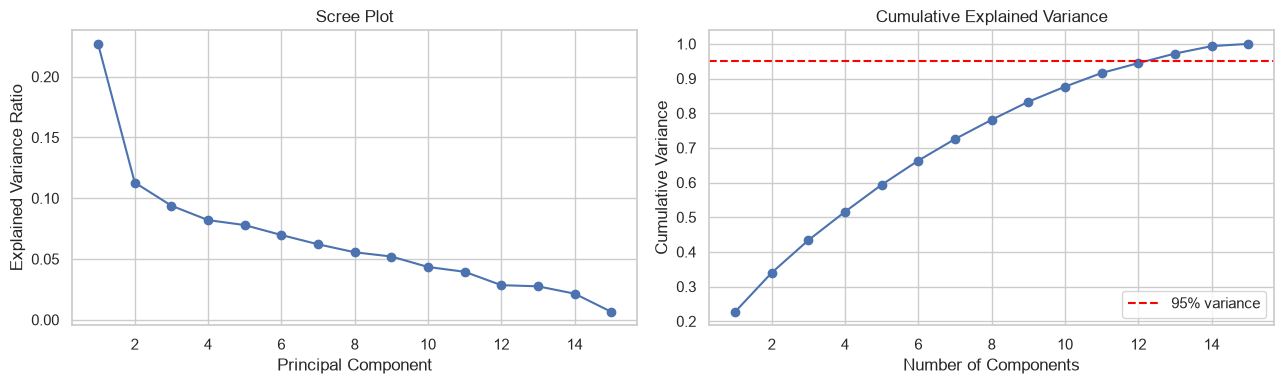

In [33]:
pca_full = PCA()
pca_full.fit(X_train_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, len(explained) + 1), explained, marker="o")
axes[0].set(title="Scree Plot", xlabel="Principal Component", ylabel="Explained Variance Ratio")
axes[1].plot(range(1, len(cumulative) + 1), cumulative, marker="o")
axes[1].axhline(0.95, color="red", linestyle="--", label="95% variance")
axes[1].set(title="Cumulative Explained Variance", xlabel="Number of Components", ylabel="Cumulative Variance")
axes[1].legend()
plt.tight_layout()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [34]:
n_components_95 = int(np.argmax(cumulative >= 0.95) + 1)
print("Components required for at least 95% variance:", n_components_95)
print("Original number of features:", X_train_scaled.shape[1])
print("Feature reduction (%):", round(
    (1 - n_components_95 / X_train_scaled.shape[1]) * 100, 2
))

Components required for at least 95% variance: 13
Original number of features: 15
Feature reduction (%): 13.33


### 7.3 Transform the training and testing sets

In [35]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("PCA components retained:", pca.n_components_)
print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA: ", X_test_pca.shape)
print("Explained variance retained:", round(pca.explained_variance_ratio_.sum(), 4))

PCA components retained: 13
Training shape after PCA: (719, 13)
Testing shape after PCA:  (180, 13)
Explained variance retained: 0.972


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

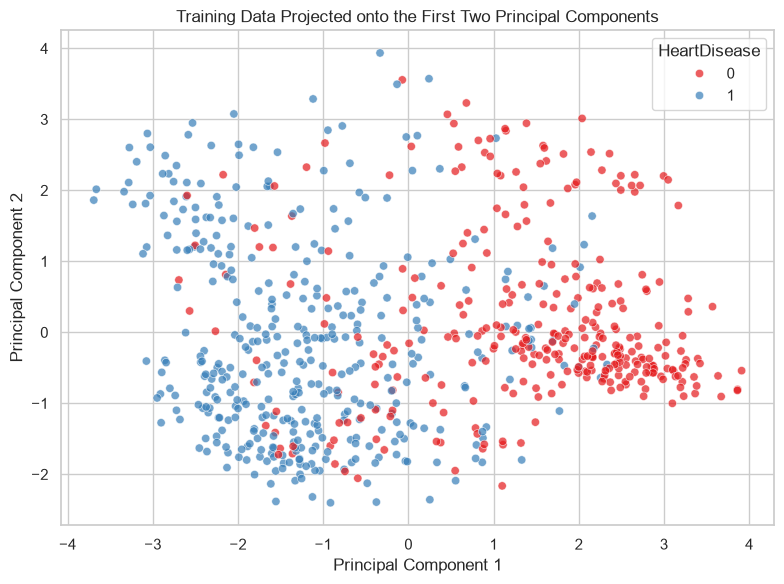

In [36]:
# Optional 2-D visualisation (uses the first two components, if available).
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_train_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y_train.to_numpy(),
                palette="Set1", alpha=0.7)
plt.title("Training Data Projected onto the First Two Principal Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="HeartDisease")
plt.tight_layout()
plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

**Answer:** The number of principal components required to retain at least 95% of the variance is printed in section 7.2 (`n_components_95`). The percentage reduction is calculated as `(1 − retained components / original encoded predictors) × 100`. Use the exact values printed by the notebook because the component count depends on the cleaned dataset and the training split.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [37]:
knn_pca_search = GridSearchCV(
    KNeighborsClassifier(), param_grids["KNN"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
knn_pca_search.fit(X_train_pca, y_train)
knn_pca_metrics, knn_pca_model, knn_pca_pred = evaluate_model(
    knn_pca_search.best_estimator_, X_train_pca, X_test_pca,
    y_train, y_test, "KNN after PCA"
)
print("Best parameters:", knn_pca_search.best_params_)
print("Best CV F1:", knn_pca_search.best_score_)


KNN after PCA
              precision    recall  f1-score   support

           0       0.92      0.88      0.90        81
           1       0.90      0.94      0.92        99

    accuracy                           0.91       180
   macro avg       0.91      0.91      0.91       180
weighted avg       0.91      0.91      0.91       180

Confusion matrix:
 [[71 10]
 [ 6 93]]
Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best CV F1: 0.8844401799633081


### 8.2 Logistic Regression after PCA

In [38]:
lr_pca_search = GridSearchCV(
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    param_grids["Logistic Regression"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
lr_pca_search.fit(X_train_pca, y_train)
lr_pca_metrics, lr_pca_model, lr_pca_pred = evaluate_model(
    lr_pca_search.best_estimator_, X_train_pca, X_test_pca,
    y_train, y_test, "Logistic Regression after PCA"
)
print("Best parameters:", lr_pca_search.best_params_)
print("Best CV F1:", lr_pca_search.best_score_)


Logistic Regression after PCA
              precision    recall  f1-score   support

           0       0.87      0.85      0.86        81
           1       0.88      0.90      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180

Confusion matrix:
 [[69 12]
 [10 89]]
Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1: 0.8811501882019146


### 8.3 Decision Tree after PCA

In [39]:
dt_pca_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grids["Decision Tree"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
dt_pca_search.fit(X_train_pca, y_train)
dt_pca_metrics, dt_pca_model, dt_pca_pred = evaluate_model(
    dt_pca_search.best_estimator_, X_train_pca, X_test_pca,
    y_train, y_test, "Decision Tree after PCA"
)
print("Best parameters:", dt_pca_search.best_params_)
print("Best CV F1:", dt_pca_search.best_score_)


Decision Tree after PCA
              precision    recall  f1-score   support

           0       0.86      0.85      0.86        81
           1       0.88      0.89      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180

Confusion matrix:
 [[69 12]
 [11 88]]
Best parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1: 0.8523042953251683


### 8.4 Random Forest after PCA

In [40]:
rf_pca_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grids["Random Forest"], cv=cv, scoring="f1",
    n_jobs=-1, refit=True
)
rf_pca_search.fit(X_train_pca, y_train)
rf_pca_metrics, rf_pca_model, rf_pca_pred = evaluate_model(
    rf_pca_search.best_estimator_, X_train_pca, X_test_pca,
    y_train, y_test, "Random Forest after PCA"
)
print("Best parameters:", rf_pca_search.best_params_)
print("Best CV F1:", rf_pca_search.best_score_)


Random Forest after PCA
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        81
           1       0.88      0.93      0.91        99

    accuracy                           0.89       180
   macro avg       0.90      0.89      0.89       180
weighted avg       0.90      0.89      0.89       180

Confusion matrix:
 [[69 12]
 [ 7 92]]
Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1: 0.8838181270701595


### 8.5 Comparison table of all four models after PCA

In [41]:
pca_model_metrics = [
    knn_pca_metrics, lr_pca_metrics, dt_pca_metrics, rf_pca_metrics
]
pca_results_df = pd.DataFrame([
    {k: v for k, v in m.items() if k != "Confusion matrix"}
    for m in pca_model_metrics
]).set_index("Model")
display(pca_results_df.round(4))

,Accuracy,Precision,Recall,F1-score,Training time (s)
Model,,,,,
KNN after PCA,0.9111,0.9029,0.9394,0.9208,0.0005
Logistic Regression after PCA,0.8778,0.8812,0.8990,0.8900,0.0012
Decision Tree after PCA,0.8722,0.8800,0.8889,0.8844,0.0025
Random Forest after PCA,0.8944,0.8846,0.9293,0.9064,0.0923


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

**Answer:** The best model after PCA is the model with the highest test metric in the section 8.5 table. Compare that row with the tuned-model table from section 6.6 to determine whether it is also the best model before PCA. Use F1-score and recall alongside accuracy, particularly because missing a positive heart-disease case is costly.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features Before,No. of Features After
KNN,0.8944,0.9111,0.9055,0.9208,0.0053,0.0005,15,13
Logistic Regression,0.8778,0.8778,0.8911,0.8900,0.0018,0.0012,15,13
Decision Tree,0.8222,0.8722,0.8298,0.8844,0.0019,0.0025,15,13
Random Forest,0.8722,0.8944,0.8878,0.9064,0.0788,0.0923,15,13


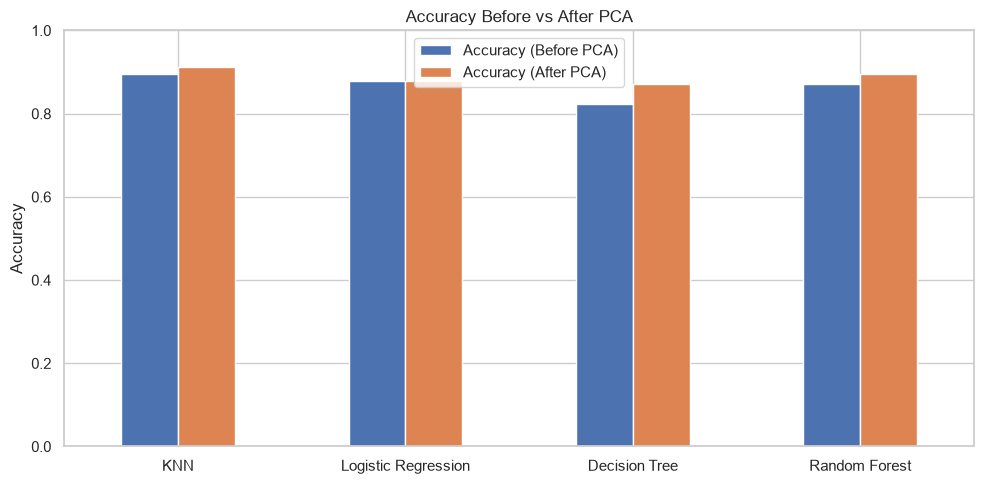

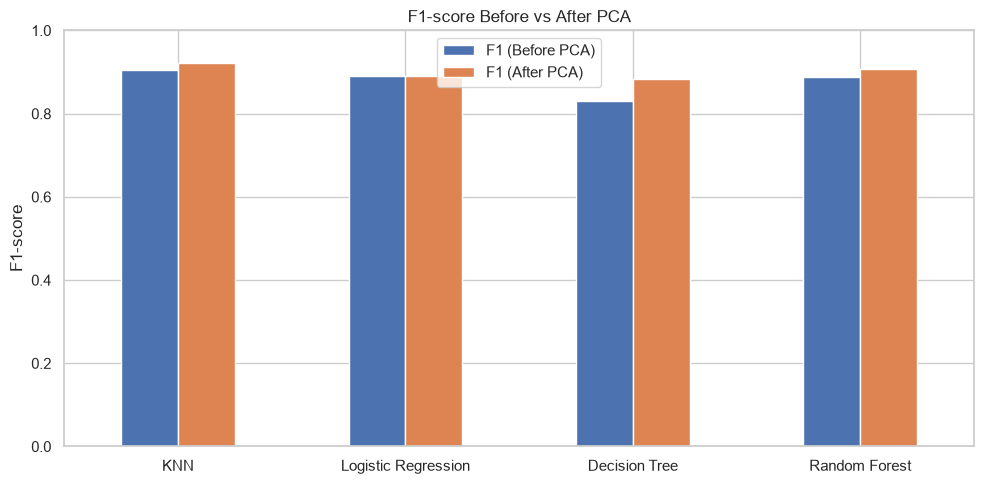

In [43]:
# Compare tuned models before and after PCA

model_names = [
    "KNN",
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

# Before PCA: use the actual index names from Task 6
before = {
    name: tuned_results_df.loc[f"{name} (tuned)"]
    for name in model_names
}

# After PCA
after = {
    "KNN": knn_pca_metrics,
    "Logistic Regression": lr_pca_metrics,
    "Decision Tree": dt_pca_metrics,
    "Random Forest": rf_pca_metrics
}

comparison = pd.DataFrame(index=model_names)

comparison["Accuracy (Before PCA)"] = [
    before[m]["Accuracy"] for m in model_names
]
comparison["Accuracy (After PCA)"] = [
    after[m]["Accuracy"] for m in model_names
]

comparison["F1 (Before PCA)"] = [
    before[m]["F1-score"] for m in model_names
]
comparison["F1 (After PCA)"] = [
    after[m]["F1-score"] for m in model_names
]

comparison["Training Time Before (s)"] = [
    before[m]["Training time (s)"] for m in model_names
]
comparison["Training Time After (s)"] = [
    after[m]["Training time (s)"] for m in model_names
]

comparison["No. of Features Before"] = X_train_scaled.shape[1]
comparison["No. of Features After"] = X_train_pca.shape[1]

display(comparison.round(4))

# Accuracy comparison
comparison[
    ["Accuracy (Before PCA)", "Accuracy (After PCA)"]
].plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)

plt.title("Accuracy Before vs After PCA")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

# F1-score comparison
comparison[
    ["F1 (Before PCA)", "F1 (After PCA)"]
].plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)

plt.title("F1-score Before vs After PCA")
plt.ylabel("F1-score")
plt.tight_layout()
plt.show()

### 9.2 Visualise the before vs after PCA comparison

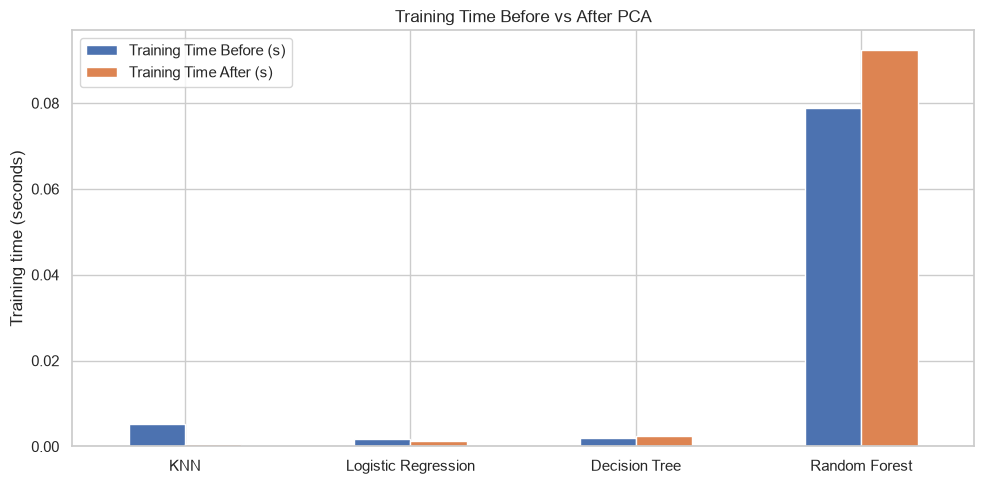

In [44]:
time_comparison = comparison[["Training Time Before (s)", "Training Time After (s)"]]
time_comparison.plot(kind="bar", figsize=(10, 5), rot=0)
plt.title("Training Time Before vs After PCA")
plt.ylabel("Training time (seconds)")
plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

**Answer:** Compare the before-PCA and after-PCA accuracy and F1 columns in the consolidated table. A positive difference means that model improved after PCA; a negative difference means it declined. The exact direction and size of the change are dataset- and model-dependent, so they should be taken from the measured results rather than assumed in advance.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

**Answer:** PCA reduces the number of input features to the number of retained principal components (the exact counts are shown in section 7.2 and the comparison table). A smaller feature space can reduce the cost of fitting and predicting, especially for algorithms whose work depends on the number of features. However, PCA itself has a fitting and transformation cost, and the total time depends on the algorithm and dataset. Training-time measurements can also vary with the computer and system load.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

**Answer:** PCA may improve, preserve, or reduce classification performance. It can remove redundancy and noise by retaining directions with high variance, which may help some models. However, directions with low variance can still contain information useful for predicting the target. PCA also creates combinations of original features, which can make the results harder to interpret. Tree-based models may be less helped by PCA because their splits use the original feature values, while distance-based models such as KNN can benefit from a compact, scaled representation. The measured comparison table determines what happened in this run.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

**Answer:** Using all features can preserve information and make the model easier to interpret, but may increase computation and retain redundant or noisy variables. PCA reduces dimensionality and can improve efficiency, but it adds preprocessing cost, reduces direct feature interpretability, and may discard predictive information. I would prefer PCA when a dataset has many correlated numerical features, computational resources are limited, or a compact representation is needed. I would retain the original features when interpretability is essential (as in explaining clinical risk factors) or when PCA reduces recall or other important predictive metrics.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.